# U-Net : reproduction pas à pas de l'article de Ronneberger, Fischer et Brox (2015)

Ce notebook c'est une vérification par le code ce que les auteurs de l'article U-Net: Convolutional Networks for Biomedical Image Segmentation avancent : on construit chaque ingrédient de la méthode, on le teste, et on regarde ce qu'il produit.

Le notebook suit l'ordre de l'article :

1. l'architecture et l'arithmétique des tailles (pourquoi 572 donne 388) ;
2. un petit jeu de données de cellules synthétiques, faute d'accès aux données ISBI ;
3. la carte de poids qui sépare les cellules en contact (équation 2 de l'article) ;
4. les déformations élastiques utilisées pour l'augmentation de données ;
5. l'initialisation des poids de He ;
6. la stratégie de découpage en tuiles avec extrapolation par miroir (*overlap-tile*) ;
7. l'implémentation PyTorch du réseau, de la perte pondérée et de l'entraînement ;
8. l'évaluation par l'IoU.

In [17]:
# Bibliothèques utilisées dans les sections 1 à 6
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from scipy import ndimage as ndi

# Graine fixe : on veut retrouver les mêmes figures à chaque exécution
SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "font.size": 9})
print("Bibliothèques chargées. NumPy", np.__version__, "| OpenCV", cv2.__version__)

Bibliothèques chargées. NumPy 2.4.6 | OpenCV 5.0.0


## L'architecture et l'arithmétique des tailles

Le chemin contractant répète deux convolutions 3×3 **sans padding** (chacune retire 2 pixels de large et de haut), puis un max-pooling 2×2 qui divise la taille par deux. À chaque étape, le nombre de canaux double. Le chemin expansif fait l'opération inverse : une « up-convolution » 2×2 double la taille et divise les canaux par deux, on concatène la carte correspondante de l'encodeur (rognée au centre), puis on applique deux convolutions 3×3. Une convolution 1×1 termine le réseau.

Comme les convolutions n'ajoutent pas de bordure, la sortie est plus petite que l'entrée. Ce n'est pas un détail : toute la stratégie de tuiles en dépend. La fonction ci-dessous suit les tailles de bout en bout, vérifie que chaque max-pooling reçoit bien une taille paire (condition posée par les auteurs) et compte les couches convolutives.

In [18]:
def trace_unet(in_size=572, depth=4, base=64, n_classes=2, verbose=True):
    # Suit les tailles et les canaux dans un U-Net sans padding.
    # Renvoie un dictionnaire contenant les tailles utiles pour le schéma.
    rows = []
    s, ch = in_size, 1
    enc = []                                   # (taille après les 2 convs, canaux)
    for d in range(depth):
        f = base * 2 ** d
        s_in = s
        s = s - 2 - 2                          # deux convolutions 3x3 valides
        if s <= 0:
            raise ValueError("Tuile d'entrée trop petite pour cette profondeur.")
        rows.append((f"Encodeur {d+1}", "2 x conv 3x3 + ReLU", f"{s_in} -> {s}", f"{ch} -> {f}"))
        enc.append((s, f))
        if s % 2 != 0:
            raise ValueError(f"Max-pooling impossible : taille {s} impaire à l'étape {d+1}.")
        s_pool = s // 2
        rows.append((f"Pooling {d+1}", "max pool 2x2", f"{s} -> {s_pool}", f"{f} -> {f}"))
        s, ch = s_pool, f
    f = base * 2 ** depth
    s_in = s
    s = s - 4
    if s <= 0:
        raise ValueError("Tuile d'entrée trop petite pour cette profondeur.")
    rows.append(("Goulot", "2 x conv 3x3 + ReLU", f"{s_in} -> {s}", f"{ch} -> {f}"))
    bott = (s, f)
    ch = f
    dec = []
    for d in reversed(range(depth)):
        f = base * 2 ** d
        s_up = s * 2
        rows.append((f"Décodeur {depth-d}", "up-conv 2x2 (x2)", f"{s} -> {s_up}", f"{ch} -> {f}"))
        s_skip, _ = enc[d]
        rows.append((f"  concat. {depth-d}", f"copie + rognage ({s_skip} -> {s_up})", f"{s_up}", f"{f} + {f} = {2*f}"))
        s_out = s_up - 4
        if s_out <= 0:
            raise ValueError("Tuile d'entrée trop petite pour cette profondeur.")
        rows.append(("", "2 x conv 3x3 + ReLU", f"{s_up} -> {s_out}", f"{2*f} -> {f}"))
        dec.append((s_out, f))
        s, ch = s_out, f
    rows.append(("Sortie", "conv 1x1", f"{s}", f"{ch} -> {n_classes}"))
    n_conv = 2 * depth + 2 + depth + 2 * depth + 1       # 3x3 + up-conv + 3x3 + 1x1
    if verbose:
        print(f"{'Étape':<14}{'Opération':<34}{'Taille':<14}{'Canaux'}")
        print("-" * 76)
        for r in rows:
            print(f"{r[0]:<14}{r[1]:<34}{r[2]:<14}{r[3]}")
        print("-" * 76)
        print(f"Taille de sortie : {s} x {s}  |  perte de bordure : {(in_size - s)//2} pixels de chaque côté")
        print(f"Couches convolutives (3x3, up-conv 2x2 et 1x1) : {n_conv}")
    return dict(enc=enc, bott=bott, dec=dec, out=s, n_conv=n_conv, in_size=in_size, depth=depth, base=base)

info = trace_unet(572)
assert info["out"] == 388 and info["n_conv"] == 23     # valeurs annoncées par l'article
print("\nVérification : 572 -> 388 et 23 couches, comme dans l'article.")

Étape         Opération                         Taille        Canaux
----------------------------------------------------------------------------
Encodeur 1    2 x conv 3x3 + ReLU               572 -> 568    1 -> 64
Pooling 1     max pool 2x2                      568 -> 284    64 -> 64
Encodeur 2    2 x conv 3x3 + ReLU               284 -> 280    64 -> 128
Pooling 2     max pool 2x2                      280 -> 140    128 -> 128
Encodeur 3    2 x conv 3x3 + ReLU               140 -> 136    128 -> 256
Pooling 3     max pool 2x2                      136 -> 68     256 -> 256
Encodeur 4    2 x conv 3x3 + ReLU               68 -> 64      256 -> 512
Pooling 4     max pool 2x2                      64 -> 32      512 -> 512
Goulot        2 x conv 3x3 + ReLU               32 -> 28      512 -> 1024
Décodeur 1    up-conv 2x2 (x2)                  28 -> 56      1024 -> 512
  concat. 1   copie + rognage (64 -> 56)        56            512 + 512 = 1024
              2 x conv 3x3 + ReLU               5

On retrouve bien les chiffres de la figure 1 de l'article : une tuile de 572×572 donne une segmentation de 388×388, et le réseau compte 23 couches convolutives (18 convolutions 3×3, 4 up-convolutions, 1 convolution 1×1).

Toutes les tailles d'entrée ne sont pas permises. Il faut que chaque max-pooling reçoive une taille paire ; la boucle ci-dessous liste les tailles admissibles pour la profondeur de l'article.

In [19]:
def valid_input_sizes(depth=4, lo=60, hi=700):
    ok = []
    for s in range(lo, hi):
        try:
            out = trace_unet(s, depth=depth, verbose=False)["out"]
            ok.append((s, out))
        except ValueError:
            pass
    return ok

sizes = valid_input_sizes()
print("Tailles d'entrée valides (entrée -> sortie), profondeur 4 :")
print(", ".join(f"{a}->{b}" for a, b in sizes[:10]), "...")
print(f"\nIl y en a {len(sizes)} entre 60 et 700. Elles sont espacées de 16 : deux tuiles valides")
print("voisines diffèrent de 16 pixels, soit 2^depth, car chaque pooling impose la parité.")
margins = {(a - b) // 2 for a, b in sizes}
print("Marge perdue de chaque côté (toujours identique) :", margins)

Tailles d'entrée valides (entrée -> sortie), profondeur 4 :
188->4, 204->20, 220->36, 236->52, 252->68, 268->84, 284->100, 300->116, 316->132, 332->148 ...

Il y en a 32 entre 60 et 700. Elles sont espacées de 16 : deux tuiles valides
voisines diffèrent de 16 pixels, soit 2^depth, car chaque pooling impose la parité.
Marge perdue de chaque côté (toujours identique) : {92}


Le nombre de paramètres se calcule à la main : une convolution 3×3 de *c_in* vers *c_out* canaux en porte 9·c_in·c_out + c_out, une up-convolution 2×2 en porte 4·c_in·c_out + c_out. Cette formule sera comparée plus loin au décompte de PyTorch.

In [20]:
def count_params(depth=4, base=64, in_ch=1, n_classes=2):
    conv3 = lambda cin, cout: 9 * cin * cout + cout
    up    = lambda cin, cout: 4 * cin * cout + cout
    total, c = 0, in_ch
    for d in range(depth):                      # encodeur
        f = base * 2 ** d
        total += conv3(c, f) + conv3(f, f); c = f
    f = base * 2 ** depth                       # goulot
    total += conv3(c, f) + conv3(f, f); c = f
    for d in reversed(range(depth)):            # décodeur
        f = base * 2 ** d
        total += up(c, f) + conv3(2 * f, f) + conv3(f, f); c = f
    total += c * n_classes + n_classes          # convolution 1x1 finale
    return total

p_full  = count_params(base=64)
p_small = count_params(base=16)
print(f"U-Net de l'article (base = 64) : {p_full:,} paramètres".replace(",", " "))
print(f"Version allégée     (base = 16) : {p_small:,} paramètres".replace(",", " "))
print(f"Rapport : {p_full / p_small:.1f} (le coût varie comme le carré du nombre de canaux)")

U-Net de l'article (base = 64) : 31 030 658 paramètres
Version allégée     (base = 16) : 1 940 834 paramètres
Rapport : 16.0 (le coût varie comme le carré du nombre de canaux)


### Schéma de l'architecture

Le schéma ci-dessous est généré à partir des tailles calculées plus haut, il ne s'agit donc pas d'un dessin figé : si l'on change la profondeur ou la tuile d'entrée, il se met à jour.

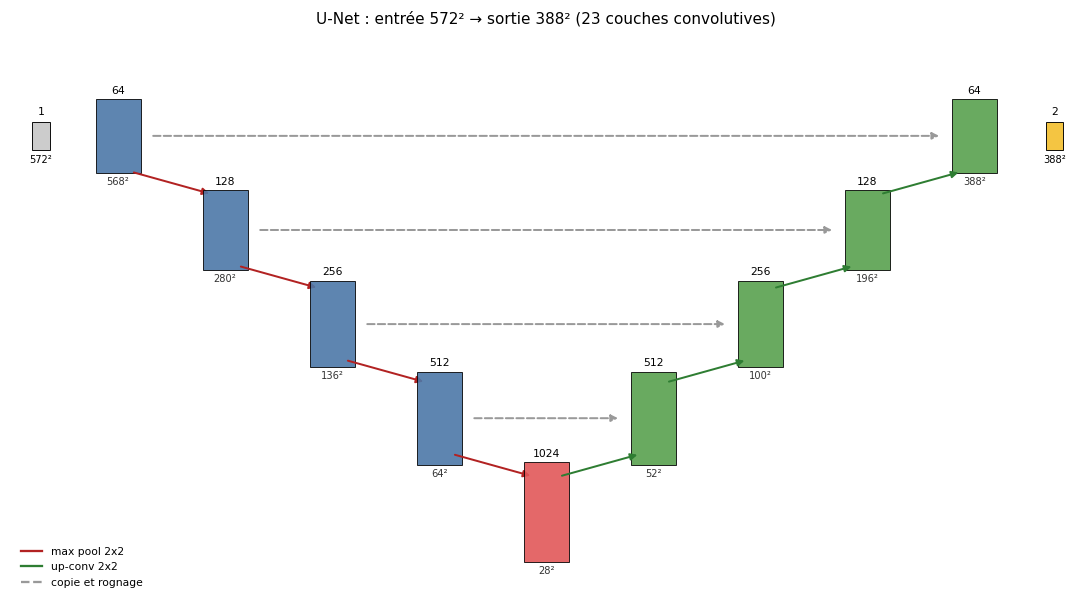

In [21]:
def draw_unet(info, ax=None):
    # Dessine le U : encodeur à gauche, goulot en bas, décodeur à droite.
    depth = info["depth"]
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5.6))
    ax.set_xlim(-1.0, 2 * depth + 1.0); ax.set_ylim(depth + 0.9, -1.1); ax.axis("off")
    c_enc, c_dec, c_bot = "#4c78a8", "#59a14f", "#e15759"

    def box(x, y, ch, size, color):
        w, h = 0.42, 0.36 + 0.07 * math.log2(ch)
        ax.add_patch(Rectangle((x - w / 2, y - h / 2), w, h, fc=color, ec="black", lw=0.6, alpha=0.9))
        ax.text(x, y - h / 2 - 0.04, f"{ch}", ha="center", va="bottom", fontsize=7)
        ax.text(x, y + h / 2 + 0.04, f"{size}²", ha="center", va="top", fontsize=6.5, color="#333")
        return h

    def arrow(p, q, color, ls="-"):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, color=color, lw=1.3, ls=ls))

    # Encodeur (x = d, y = d), puis goulot, puis décodeur symétrique
    for d, (s, f) in enumerate(info["enc"]):
        box(d, d, f, s, c_enc)
        arrow((d + 0.12, d + 0.38), (d + 0.88, d + 0.62), "#b22222")                 # max pool
    sb, fb = info["bott"]
    box(depth, depth, fb, sb, c_bot)
    for k, (s, f) in enumerate(info["dec"]):
        d = depth - 1 - k
        x = 2 * depth - d
        box(x, d, f, s, c_dec)
        arrow((x - 0.88, d + 0.62), (x - 0.12, d + 0.38), "#2e7d32")                  # up-conv
        arrow((d + 0.3, d), (x - 0.3, d), "#999999", ls="--")                         # copie et rognage
    box_in = ax.add_patch(Rectangle((-0.8, -0.15), 0.16, 0.3, fc="#cccccc", ec="black", lw=0.6))
    ax.text(-0.72, -0.2, "1", ha="center", va="bottom", fontsize=7)
    ax.text(-0.72, 0.2, f"{info['in_size']}²", ha="center", va="top", fontsize=6.5)
    ax.text(2 * depth + 0.75, -0.2, "2", ha="center", va="bottom", fontsize=7)
    ax.text(2 * depth + 0.75, 0.2, f"{info['out']}²", ha="center", va="top", fontsize=6.5)
    ax.add_patch(Rectangle((2 * depth + 0.67, -0.15), 0.16, 0.3, fc="#f4c542", ec="black", lw=0.6))
    ax.plot([], [], color="#b22222", label="max pool 2x2"); ax.plot([], [], color="#2e7d32", label="up-conv 2x2")
    ax.plot([], [], color="#999999", ls="--", label="copie et rognage")
    ax.legend(loc="lower left", fontsize=7, frameon=False)
    ax.set_title(f"U-Net : entrée {info['in_size']}² → sortie {info['out']}² ({info['n_conv']} couches convolutives)")
    return ax

fig, ax = plt.subplots(figsize=(10, 5.6))
draw_unet(info, ax)
fig.tight_layout(); fig.savefig("fig_architecture.png", dpi=160); plt.show()

## Un jeu de données synthétique de cellules en contact


Image : (256, 256), valeurs dans [0.03, 0.86]
Cellules visibles : 14 | pixels de cellule : 50.5% | fond : 49.5%


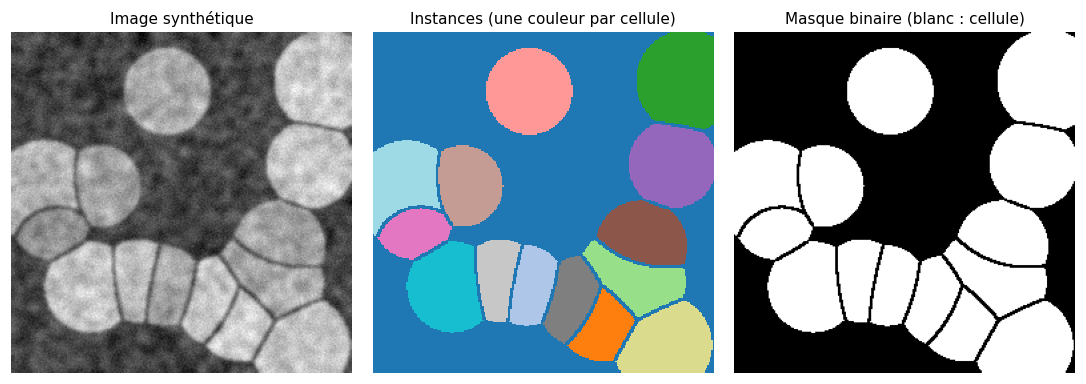

In [22]:
def make_synthetic_sample(size=256, n_cells=14, r_range=(28, 42), rng=None):
    # Renvoie (image, labels) : image en [0, 1], labels entiers (0 = fond, k >= 1 = cellule k).
    rng = rng if rng is not None else np.random.default_rng()
    yy, xx = np.mgrid[0:size, 0:size]
    centers = rng.uniform(15, size - 15, size=(n_cells, 2))
    radii = rng.uniform(*r_range, size=n_cells)

    # Distance normalisée de chaque pixel à chaque centre
    d = np.stack([np.hypot(yy - cy, xx - cx) / r for (cy, cx), r in zip(centers, radii)])
    nearest, dmin = d.argmin(axis=0), d.min(axis=0)
    labels = np.where(dmin < 1.0, nearest + 1, 0)

    # Fine bordure de fond entre deux cellules qui se touchent
    big = 10 ** 6
    mx = ndi.maximum_filter(labels, size=3)
    mn = ndi.minimum_filter(np.where(labels == 0, big, labels), size=3)
    border = (labels > 0) & (mn != big) & (mx != mn)
    labels = np.where(border, 0, labels)

    # Rendu de l'image : fond sombre, cellules plus claires, texture, flou, bruit
    per_cell = rng.uniform(-0.10, 0.10, size=n_cells + 1); per_cell[0] = 0
    img = np.where(labels > 0, 0.62, 0.25) + per_cell[labels]
    img += 0.10 * ndi.gaussian_filter(rng.normal(size=(size, size)), 2.5) * 4
    img = ndi.gaussian_filter(img, 1.2) + rng.normal(0, 0.03, size=(size, size))
    return np.clip(img, 0, 1).astype(np.float32), labels.astype(np.int32)

img, lab = make_synthetic_sample(256, rng=np.random.default_rng(SEED))
fg = (lab > 0).astype(np.uint8)
print(f"Image : {img.shape}, valeurs dans [{img.min():.2f}, {img.max():.2f}]")
print(f"Cellules visibles : {len(np.unique(lab)) - 1} | pixels de cellule : {fg.mean():.1%} | fond : {1 - fg.mean():.1%}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
axs[0].imshow(img, cmap="gray"); axs[0].set_title("Image synthétique")
axs[1].imshow(lab, cmap="tab20", interpolation="nearest"); axs[1].set_title("Instances (une couleur par cellule)")
axs[2].imshow(fg, cmap="gray"); axs[2].set_title("Masque binaire (blanc : cellule)")
for a in axs: a.axis("off")
fig.tight_layout(); fig.savefig("fig_donnees.png", dpi=150); plt.show()

On voit sur le masque binaire que les cellules voisines sont séparées par un filet noir très fin. C'est ce filet qui pose problème à un réseau entraîné avec une perte classique : il représente une toute petite fraction des pixels, donc une erreur à cet endroit coûte presque rien, et le réseau finit par fusionner les cellules. La section suivante répond à ce problème.

## La carte de poids de l'équation (2)


In [ ]:
def weight_map(labels, w0=10.0, sigma=5.0):
    # Carte de poids de l'équation (2) de l'article, pour une segmentation par instances.
    fg = labels > 0
    p_fg = fg.mean()
    # w_c : rééquilibrage des classes (chaque classe pèse autant au total)
    wc = np.where(fg, 0.5 / p_fg, 0.5 / (1 - p_fg))

    ids = [k for k in np.unique(labels) if k != 0]
    if len(ids) < 2:
        return wc.astype(np.float32)
    # Distance de chaque pixel à chaque cellule, puis on garde les deux plus petites
    dists = np.stack([ndi.distance_transform_edt(labels != k) for k in ids])
    dists.sort(axis=0)
    d1, d2 = dists[0], dists[1]
    border_term = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))
    return (wc + border_term * (~fg)).astype(np.float32)

wmap = weight_map(lab)
print(f"Poids minimal : {wmap.min():.2f} | médian : {np.median(wmap):.2f} | maximal : {wmap.max():.2f}")
print(f"Poids moyen des pixels de cellule : {wmap[fg == 1].mean():.2f}")
print(f"Poids moyen des pixels de fond    : {wmap[fg == 0].mean():.2f}")
thin = (fg == 0) & (wmap > 5)
print(f"Pixels de fond avec un poids > 5 : {thin.sum()} ({thin.sum() / (fg == 0).sum():.1%} du fond)")

fig, axs = plt.subplots(1, 3, figsize=(11, 3.5))
axs[0].imshow(fg, cmap="gray"); axs[0].set_title("Masque binaire")
im = axs[1].imshow(wmap, cmap="jet"); axs[1].set_title("Carte de poids w(x)")
fig.colorbar(im, ax=axs[1], fraction=0.046)
axs[2].imshow(img, cmap="gray"); axs[2].imshow(np.ma.masked_where(wmap < 5, wmap), cmap="autumn", alpha=0.9)
axs[2].set_title("Pixels à fort poids (> 5) sur l'image")
for a in axs: a.axis("off")
fig.tight_layout(); fig.savefig("fig_poids.png", dpi=150); plt.show()

Poids minimal : 0.99 | médian : 0.99 | maximal : 9.91
Poids moyen des pixels de cellule : 0.99
Poids moyen des pixels de fond    : 1.52
Pixels de fond avec un poids > 5 : 1926 (5.9% du fond)


Les zones rouges de la carte correspondent exactement aux filets entre cellules voisines, comme sur la figure 3d de l'article. Avec ces poids, une erreur sur un filet de séparation coûte une dizaine de fois plus qu'une erreur ailleurs, ce qui oblige le réseau à les apprendre.

## Déformations élastiques

Les auteurs présentent les déformations élastiques comme la clé pour entraîner un réseau avec très peu d'images. Leur recette : tirer des vecteurs de déplacement aléatoires sur une grille grossière 3×3 (loi gaussienne d'écart-type 10 pixels), puis interpoler en bicubique pour obtenir un déplacement en chaque pixel. L'image, le masque et la carte de poids doivent subir **la même** déformation, avec des interpolations adaptées : cubique pour l'image, plus proche voisin pour les étiquettes (on ne veut pas inventer de classe intermédiaire), linéaire pour les poids.

In [ ]:
def elastic_deform(arrays, orders, grid=3, sigma=10.0, rng=None):
    # Applique la même déformation élastique à une liste de tableaux 2D de même taille.
    rng = rng if rng is not None else np.random.default_rng()
    H, W = arrays[0].shape
    # Déplacements tirés sur une grille grossière, puis interpolés (bicubique) à pleine résolution
    dx = cv2.resize(rng.normal(0, sigma, (grid, grid)).astype(np.float32), (W, H), interpolation=cv2.INTER_CUBIC)
    dy = cv2.resize(rng.normal(0, sigma, (grid, grid)).astype(np.float32), (W, H), interpolation=cv2.INTER_CUBIC)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    coords = np.stack([yy + dy, xx + dx])
    out = [ndi.map_coordinates(a, coords, order=o, mode="reflect") for a, o in zip(arrays, orders)]
    return out, dx, dy

# Grille régulière tracée dans l'image pour rendre la déformation visible
grid_img = np.zeros_like(img)
grid_img[::16, :] = 1; grid_img[:, ::16] = 1

(img_d, lab_d, w_d, grid_d), dx, dy = elastic_deform(
    [img, lab.astype(np.float32), wmap, grid_img], orders=[3, 0, 1, 1],
    rng=np.random.default_rng(7))
lab_d = lab_d.astype(np.int32)

mag = np.hypot(dx, dy)
print(f"Déplacement moyen : {mag.mean():.1f} px | maximal : {mag.max():.1f} px")
print("Étiquettes avant :", [int(v) for v in np.unique(lab)[:5]], "... | après :", [int(v) for v in np.unique(lab_d)[:5]], "...")
print("Valeurs d'étiquette nouvelles après déformation :", set(np.unique(lab_d)) - set(np.unique(lab)) or "aucune")
print(f"Cellules conservées : {len(np.unique(lab_d)) - 1} sur {len(np.unique(lab)) - 1}")

fig, axs = plt.subplots(2, 3, figsize=(10.5, 7))
axs[0, 0].imshow(img, cmap="gray");  axs[0, 0].set_title("Image originale")
axs[0, 1].imshow(grid_img, cmap="gray"); axs[0, 1].set_title("Grille régulière")
axs[0, 2].imshow(lab, cmap="tab20", interpolation="nearest"); axs[0, 2].set_title("Étiquettes originales")
axs[1, 0].imshow(img_d, cmap="gray"); axs[1, 0].set_title("Image déformée")
axs[1, 1].imshow(grid_d, cmap="gray"); axs[1, 1].set_title("Grille déformée")
axs[1, 2].imshow(lab_d, cmap="tab20", interpolation="nearest"); axs[1, 2].set_title("Étiquettes déformées")
for a in axs.ravel(): a.axis("off")
fig.tight_layout(); fig.savefig("fig_elastique.png", dpi=150); plt.show()

La grille déformée montre un champ de déplacement doux : les lignes restent continues, aucune cellule n'est déchirée. Les étiquettes suivent l'image, et aucune valeur nouvelle n'apparaît. C'est ce qui rend l'augmentation « réaliste » pour des tissus : une cellule réelle se déforme de façon continue, et le réseau apprend à ne pas en tenir rigueur sans qu'il faille annoter ces variantes.

##  L'initialisation de He

L'article insiste sur l'initialisation : dans un réseau profond avec plusieurs chemins, un mauvais départ fait exploser certaines activations et éteint les autres. La règle retenue est une gaussienne d'écart-type $\sqrt{2/N}$, où $N$ est le nombre d'entrées d'un neurone (par exemple $N = 9 \times 64 = 576$ pour une convolution 3×3 sur 64 canaux).

On peut le vérifier avec une petite expérience : on empile 30 couches denses de largeur 576 suivies de ReLU, et on suit l'amplitude (valeur quadratique moyenne) des activations selon l'écart-type choisi pour les poids.

In [ ]:
N, n_layers = 9 * 64, 30
print(f"N = {N} -> écart-type de He : sqrt(2/N) = {math.sqrt(2 / N):.4f}\n")

def activation_profile(std, n_layers=30, N=576, seed=0):
    r = np.random.default_rng(seed)
    h = r.normal(size=(1000, N))                     # entrées de variance 1
    rms = []
    for _ in range(n_layers):
        h = np.maximum(h @ r.normal(0, std, (N, N)), 0)   # couche dense + ReLU
        rms.append(np.sqrt((h ** 2).mean()))
    return rms

choices = {"σ = 0,01 (trop petit)": 0.01,
           "σ = √(1/N)": math.sqrt(1 / N),
           "σ = √(2/N) (He)": math.sqrt(2 / N)}
profiles = {k: activation_profile(v) for k, v in choices.items()}

print(f"{'Initialisation':<26}{'couche 1':>12}{'couche 10':>12}{'couche 30':>14}")
for k, p in profiles.items():
    print(f"{k:<26}{p[0]:>12.3g}{p[9]:>12.3g}{p[29]:>14.3g}")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
for k, p in profiles.items():
    ax.semilogy(range(1, n_layers + 1), p, label=k)
ax.set_xlabel("Profondeur (couche)"); ax.set_ylabel("Amplitude des activations (échelle log)")
ax.set_title("Propagation des activations selon l'initialisation"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig_he.png", dpi=150); plt.show()

Avec un écart-type trop petit, le signal s'évanouit en quelques couches. Avec $\sqrt{1/N}$, il décroît lentement, car la ReLU supprime la moitié de la variance à chaque couche. Seule l'initialisation de He maintient une amplitude stable sur toute la profondeur, ce qui justifie le facteur 2 dans $\sqrt{2/N}$.

##  Découpage en tuiles avec extrapolation par miroir (*overlap-tile*)

Puisque la sortie est plus petite que l'entrée, une grande image ne peut pas être passée d'un bloc. On la découpe en tuiles de sortie de taille $T_{out}$ qui se juxtaposent sans trou. Pour chacune, le réseau reçoit une tuile d'entrée plus grande, de côté $T_{in} = T_{out} + 2m$, où $m$ est la marge perdue sur chaque bord (92 pixels pour 572 → 388). Sur les bords de l'image, la partie manquante est remplie par réflexion.

La fonction ci-dessous implémente cette logique de façon indépendante du modèle : elle prend en argument une fonction `model_fn` qui transforme une tuile d'entrée en tuile de sortie.

In [ ]:
def predict_with_overlap_tiles(model_fn, image, in_tile, out_tile):
    # Segmente une image de taille quelconque, tuile par tuile (stratégie de la figure 2 de l'article).
    H, W = image.shape
    m = (in_tile - out_tile) // 2                     # marge perdue de chaque côté
    nH, nW = math.ceil(H / out_tile), math.ceil(W / out_tile)
    padH, padW = nH * out_tile - H, nW * out_tile - W
    # Miroir sur tous les bords (+ complément pour que l'image soit un multiple de out_tile)
    padded = np.pad(image, ((m, m + padH), (m, m + padW)), mode="reflect")
    out = np.zeros((nH * out_tile, nW * out_tile), dtype=np.float32)
    for i in range(nH):
        for j in range(nW):
            y0, x0 = i * out_tile, j * out_tile
            tile = padded[y0:y0 + in_tile, x0:x0 + in_tile]
            out[y0:y0 + out_tile, x0:x0 + out_tile] = model_fn(tile)
    return out[:H, :W], (nH, nW), m

# Test de la logique avec un « faux modèle » qui renvoie simplement le centre de la tuile.
# Si le découpage est correct, on doit retrouver l'image d'origine à l'identique.
IN_T, OUT_T = 572, 388
big_img, _ = make_synthetic_sample(900, n_cells=60, rng=np.random.default_rng(3))
fake_model = lambda t: t[(IN_T - OUT_T) // 2:(IN_T - OUT_T) // 2 + OUT_T, (IN_T - OUT_T) // 2:(IN_T - OUT_T) // 2 + OUT_T]

rebuilt, (nH, nW), m = predict_with_overlap_tiles(fake_model, big_img, IN_T, OUT_T)
print(f"Image de {big_img.shape[0]} x {big_img.shape[1]} px, tuiles {IN_T} -> {OUT_T}, marge m = {m} px")
print(f"Nombre de tuiles : {nH} x {nW} = {nH * nW}")
print(f"Erreur maximale de reconstruction : {np.abs(rebuilt - big_img).max():.2e}")
assert np.allclose(rebuilt, big_img), "Le découpage ne reconstruit pas l'image !"
print("Le découpage est sans couture : l'image est reconstruite exactement.")

# Visualisation façon figure 2 : zone d'entrée (bleu) et zone prédite (jaune) pour une tuile
padded = np.pad(big_img, m, mode="reflect")
fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.imshow(padded, cmap="gray", extent=(-m, big_img.shape[1] + m, big_img.shape[0] + m, -m))
ax.add_patch(Rectangle((0, 0), big_img.shape[1], big_img.shape[0], fill=False, ec="white", ls=":", lw=1))
i, j = 0, 1
x0, y0 = j * OUT_T, i * OUT_T
ax.add_patch(Rectangle((x0 - m, y0 - m), IN_T, IN_T, fill=False, ec="#1f77ff", lw=2, label=f"entrée {IN_T}²"))
ax.add_patch(Rectangle((x0, y0), OUT_T, OUT_T, fill=False, ec="#ffd700", lw=2, label=f"sortie {OUT_T}²"))
ax.set_title("Tuile (0, 1) : contexte d'entrée et zone prédite\n(le cadre blanc pointillé est l'image d'origine)")
ax.legend(loc="lower right", fontsize=8); ax.axis("off")
fig.tight_layout(); fig.savefig("fig_tuiles.png", dpi=150); plt.show()

##  Implémentation PyTorch


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| appareil :", device)

In [ ]:
def center_crop(t, target_hw):
    # Rogne un tenseur (B, C, H, W) au centre pour atteindre la taille (h, w) demandée.
    h, w = t.shape[-2:]
    th, tw = target_hw
    dh, dw = (h - th) // 2, (w - tw) // 2
    return t[..., dh:dh + th, dw:dw + tw]


class DoubleConv(nn.Module):
    # Deux convolutions 3x3 sans padding, chacune suivie d'une ReLU.
    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, kernel_size=3), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, kernel_size=3), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, n_classes=2, base=64, depth=4):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]          # 64, 128, 256, 512, 1024
        self.depth = depth
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Chemin contractant
        self.down = nn.ModuleList()
        c = in_channels
        for f in chs[:-1]:
            self.down.append(DoubleConv(c, f))
            c = f
        # Goulot
        self.bottleneck = DoubleConv(chs[-2], chs[-1])
        # Chemin expansif
        self.up = nn.ModuleList()
        self.dec = nn.ModuleList()
        for i in reversed(range(depth)):
            self.up.append(nn.ConvTranspose2d(chs[i + 1], chs[i], kernel_size=2, stride=2))
            self.dec.append(DoubleConv(2 * chs[i], chs[i]))
        # Convolution 1x1 finale : un score par classe et par pixel
        self.head = nn.Conv2d(chs[0], n_classes, kernel_size=1)

        self._init_weights()

    def _init_weights(self):
        # Initialisation de He : gaussienne d'écart-type sqrt(2/N), comme dans l'article.
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for block in self.down:
            x = block(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            x = torch.cat([center_crop(skip, x.shape[-2:]), x], dim=1)
            x = dec(x)
        return self.head(x)            # logits ; le softmax est inclus dans la perte

In [ ]:
# Contrôle de cohérence : mêmes tailles et même nombre de paramètres que le calcul de la section 1.
net = UNet(in_channels=1, n_classes=2, base=64).to(device)
with torch.no_grad():
    y = net(torch.randn(1, 1, 572, 572, device=device))
n_params = sum(p.numel() for p in net.parameters())
print("Sortie pour une entrée 572x572 :", tuple(y.shape))
print(f"Paramètres PyTorch : {n_params:,}  |  calcul à la main : {count_params(base=64):,}")
assert tuple(y.shape) == (1, 2, 388, 388) and n_params == count_params(base=64)
del net, y

### Perte pondérée et jeu de données d'entraînement

La perte est une entropie croisée pondérée pixel par pixel :

$$ E = -\sum_{\mathbf{x} \in \Omega} w(\mathbf{x}) \, \log p_{\ell(\mathbf{x})}(\mathbf{x}). $$

Comme la sortie est plus petite que l'entrée, les étiquettes et les poids sont rognés à la taille de la sortie. Le jeu de données applique à la volée une déformation élastique (section 4) et des rotations/retournements, puis extrait une tuile d'entrée avec marge réfléchie.

In [ ]:
def weighted_cross_entropy(logits, target, weight):
    # logits : (B, K, h, w) ; target : (B, h, w) entiers ; weight : (B, h, w) réels
    per_pixel = F.cross_entropy(logits, target, reduction="none")
    return (weight * per_pixel).mean()


# Configuration allégée : mêmes principes que l'article, mais exécutable rapidement.
BASE = 16                 # 64 dans l'article ; 16 suffit pour ce jeu synthétique
IN_TILE, OUT_TILE = 284, 100     # couple valide de la section 1 (marge de 92 px)
MARGIN = (IN_TILE - OUT_TILE) // 2


class SyntheticCells(Dataset):
    def __init__(self, samples, steps, augment=True, seed=0):
        # samples : liste de (image, labels). Les cartes de poids sont précalculées une seule fois.
        self.data = [(im, (lb > 0).astype(np.int64), weight_map(lb)) for im, lb in samples]
        self.steps, self.augment = steps, augment
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.steps

    def __getitem__(self, idx):
        im, fg, w = self.data[self.rng.integers(len(self.data))]
        if self.augment:
            (im, fg, w), _, _ = elastic_deform([im, fg.astype(np.float32), w], orders=[3, 0, 1], rng=self.rng)
            fg = fg.astype(np.int64)
            k = int(self.rng.integers(4))                       # rotation de k x 90 degrés
            im, fg, w = np.rot90(im, k), np.rot90(fg, k), np.rot90(w, k)
            if self.rng.random() < 0.5:                         # retournement horizontal
                im, fg, w = im[:, ::-1], fg[:, ::-1], w[:, ::-1]
        H, W = im.shape
        padded = np.pad(im, MARGIN, mode="reflect")
        y0 = int(self.rng.integers(0, H - OUT_TILE + 1)); x0 = int(self.rng.integers(0, W - OUT_TILE + 1))
        x_in = padded[y0:y0 + IN_TILE, x0:x0 + IN_TILE]
        y_lab = fg[y0:y0 + OUT_TILE, x0:x0 + OUT_TILE]
        y_w = w[y0:y0 + OUT_TILE, x0:x0 + OUT_TILE]
        return (torch.from_numpy(np.ascontiguousarray(x_in))[None].float(),
                torch.from_numpy(np.ascontiguousarray(y_lab)).long(),
                torch.from_numpy(np.ascontiguousarray(y_w)).float())


# 30 images d'entraînement (comme le jeu ISBI 2012) et 6 images de validation jamais vues
train_samples = [make_synthetic_sample(256, rng=np.random.default_rng(100 + i)) for i in range(30)]
val_samples   = [make_synthetic_sample(256, rng=np.random.default_rng(900 + i)) for i in range(6)]

train_ds = SyntheticCells(train_samples, steps=150, augment=True, seed=1)
# batch = 1 : l'article privilégie de grandes tuiles plutôt qu'un grand batch
train_dl = DataLoader(train_ds, batch_size=1, shuffle=False)
xb, yb, wb = next(iter(train_dl))
print("Tuile d'entrée :", tuple(xb.shape), "| étiquettes :", tuple(yb.shape), "| poids :", tuple(wb.shape))

### Entraînement

descente de gradient stochastique, **momentum élevé (0,99)** et **batch d'une seule image**. Le pas d'apprentissage n'est pas donné dans le papier ; $10^{-3}$ est une valeur raisonnable avec un tel momentum.

In [ ]:
model = UNet(in_channels=1, n_classes=2, base=BASE).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.99)

EPOCHS = 15
history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for xb, yb, wb in train_dl:
        xb, yb, wb = xb.to(device), yb.to(device), wb.to(device)
        optimizer.zero_grad()
        loss = weighted_cross_entropy(model(xb), yb, wb)
        loss.backward()
        optimizer.step()
        running += loss.item()
    history.append(running / len(train_dl))
    print(f"Époque {epoch:2d}/{EPOCHS} | perte pondérée moyenne : {history[-1]:.4f}")

plt.figure(figsize=(5.5, 3.2))
plt.plot(range(1, EPOCHS + 1), history, marker="o")
plt.xlabel("Époque"); plt.ylabel("Perte pondérée"); plt.title("Courbe d'apprentissage"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_perte.png", dpi=150); plt.show()

## Évaluation

On segmente chaque image de validation en entier avec la fonction de découpage en tuiles de la section 6 (le vrai réseau remplace le « faux modèle »), puis on calcule l'IoU, c'est-à-dire l'intersection sur l'union entre le masque prédit et le masque réel :

$$ \mathrm{IoU} = \frac{|P \cap G|}{|P \cup G|}. $$

C'est la métrique qu'on va utilise pour le défi de suivi de cellules ISBI 2015 (92 % sur PhC-U373 et 77,5 % sur DIC-HeLa). Les valeurs obtenues ici portent sur des données synthétiques simples elles servent à vérifier que la chaîne complète fonctionne.

In [ ]:
@torch.no_grad()
def model_fn(tile):
    # Transforme une tuile d'entrée (IN_TILE x IN_TILE) en carte de probabilité (OUT_TILE x OUT_TILE).
    model.eval()
    x = torch.from_numpy(np.ascontiguousarray(tile))[None, None].float().to(device)
    return torch.softmax(model(x), dim=1)[0, 1].cpu().numpy()

def iou_score(pred, truth):
    inter = np.logical_and(pred, truth).sum()
    union = np.logical_or(pred, truth).sum()
    return inter / union if union > 0 else 1.0

ious, results = [], []
for im, lb in val_samples:
    prob, _, _ = predict_with_overlap_tiles(model_fn, im, IN_TILE, OUT_TILE)
    pred, truth = prob > 0.5, lb > 0
    ious.append(iou_score(pred, truth)); results.append((im, truth, pred))

for k, v in enumerate(ious, 1):
    print(f"Image de validation {k} : IoU = {v:.3f}")
print(f"\nIoU moyen sur {len(ious)} images : {np.mean(ious):.3f}")

fig, axs = plt.subplots(3, 3, figsize=(8, 8))
for r in range(3):
    im, truth, pred = results[r]
    axs[r, 0].imshow(im, cmap="gray");    axs[r, 1].imshow(truth, cmap="gray");  axs[r, 2].imshow(pred, cmap="gray")
    for c in range(3): axs[r, c].axis("off")
axs[0, 0].set_title("Entrée"); axs[0, 1].set_title("Vérité terrain"); axs[0, 2].set_title("Prédiction")
fig.tight_layout(); fig.savefig("fig_resultats.png", dpi=150); plt.show()